In [2]:
import sys
sys.path.append("../")

from config import *
from figs_config import *

Loaded aesthetics module


In [3]:
import joblib

sphere_mesh = joblib.load(projdir + '/data/fsLR-4k_sphere_grf.pkl')

In [4]:
import numpy as np

rng = np.random.default_rng(321)

In [34]:
w = rng.normal(loc=0, scale=1, size=4002)

In [8]:
import numpy as np
from scipy.special import sph_harm

def normalize_rows(v):
    return v / np.linalg.norm(v, axis=1)[:,None]

def cartesian_to_sph(coords):
    # coords: (N,3), assumed on or near unit sphere
    x,y,z = coords[:,0], coords[:,1], coords[:,2]
    r = np.linalg.norm(coords, axis=1)
    # colatitude theta in [0, pi], longitude phi in [0, 2pi)
    theta = np.arccos(np.clip(z / r, -1.0, 1.0))
    phi = np.arctan2(y, x)
    phi = np.mod(phi, 2*np.pi)
    return theta, phi

def spherical_triangle_area(a, b, c):
    # a,b,c are 3D unit vectors (shape (3,))
    # formula: area = 2 * atan2( |(a x b) · c|, 1 + a·b + b·c + c·a )
    cross = np.cross(a, b)
    numerator = abs(np.dot(cross, c))
    denom = 1.0 + np.dot(a,b) + np.dot(b,c) + np.dot(c,a)
    return 2.0 * np.arctan2(numerator, denom)

def vertex_weights_from_faces(vertices, faces):
    # vertices: (N,3) on unit sphere
    # faces: (M,3) indices into vertices
    N = len(vertices)
    weights = np.zeros(N, dtype=float)
    for tri in faces:
        a, b, c = vertices[tri[0]], vertices[tri[1]], vertices[tri[2]]
        area = spherical_triangle_area(a, b, c)
        # distribute equally to each vertex (barycentric distribution)
        weights[tri] += area / 3.0
    return weights  # sum(weights) should be ~ 4*pi

def project_to_sh(vertices, faces, f, Lmax):
    # vertices (N,3) unit sphere, faces (M,3) indices, f (N,) scalar values
    # returns dict of complex coefficients a[(l,m)] where m in [-l..l]
    vertices = normalize_rows(np.array(vertices))
    theta, phi = cartesian_to_sph(vertices)
    weights = vertex_weights_from_faces(vertices, faces)
    # sanity: total area ~ 4*pi
    # print("total area:", weights.sum())
    coeffs = {}
    for l in range(Lmax+1):
        for m in range(-l, l+1):
            # scipy sph_harm uses args (m, l, phi, theta)
            Y_lm = sph_harm(m, l, phi, theta)  # shape (N,), complex
            a_lm = np.sum(f * np.conjugate(Y_lm) * weights)
            coeffs[(l, m)] = a_lm
    return coeffs, weights

def reconstruct_from_sh(vertices, coeffs, l=None, m=None, Lmax=None):
    vertices = normalize_rows(np.array(vertices))
    theta, phi = cartesian_to_sph(vertices)
    N = vertices.shape[0]
    f_rec = np.zeros(N, dtype=complex)

    # single harmonic

    if Lmax==None:
        Y_lm = sph_harm(m, l, phi, theta)
        f_rec = coeffs[(l,m)] * Y_lm

        return f_rec.real
    
    else:
        for l in range(Lmax+1):
            for m in range(-l, l+1):
                Y_lm = sph_harm(m, l, phi, theta)
                f_rec += coeffs[(l,m)] * Y_lm
        # If original f is real and coefficients respect conjugation symmetry, imag part ~ 0
        return f_rec.real

# Example usage:
# vertices: Nx3 array on unit sphere
# faces: Mx3 integer array (triangles)
# f: scalar values per vertex (e.g., radius)
# Lmax: chosen max degree
#
# coeffs, weights = project_to_sh(vertices, faces, f, Lmax)
# f_approx = reconstruct_from_sh(vertices, coeffs, Lmax)


In [10]:
from neuromaps.datasets import fetch_fslr

fs4 = fetch_fslr(density="4k")

In [11]:
import nibabel as nb
vertices, faces = nb.load(fs4['sphere'].L).darrays[0].data, nb.load(fs4['sphere'].L).darrays[1].data

In [15]:
from interpmodules import helpers

f = np.ones(4002)

coeffs, weights = project_to_sh(vertices, faces, f, 100)

sph_harms = dict.fromkeys(range(10))
#sph_harm = reconstruct_from_sh(vertices, coeffs, Lmax=5)
for i in range(10):
    f_approx = reconstruct_from_sh(vertices, coeffs,l=i + 1, m=i)
    sph_harms[i] = f_approx

/tmp/ipykernel_192309/3699670483.py:50: RuntimeWarning: invalid value encountered in multiply
  a_lm = np.sum(f * np.conjugate(Y_lm) * weights)


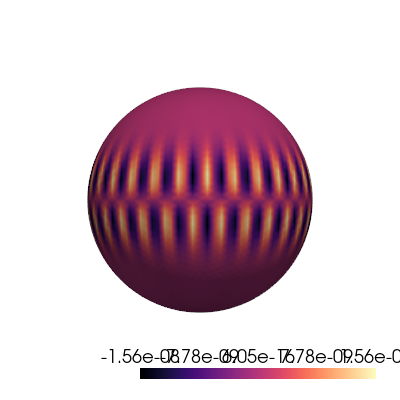

In [49]:
import pyvista as pv

i = 30

f_approx = reconstruct_from_sh(vertices, coeffs,l=i + 1, m=i)

pl = pv.Plotter(window_size = (400, 400))
pl.add_mesh(sphere_mesh, scalars=f_approx, cmap = 'magma')
pl.camera_position = 'yz'
pl.show(jupyter_backend='static')

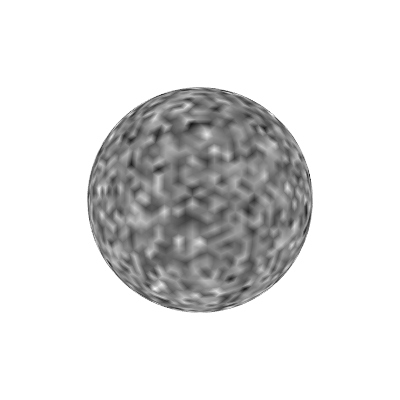

In [106]:
pl = pv.Plotter(window_size = (400, 400))
pl.add_mesh(sphere_mesh, scalars=w, cmap = 'binary', **mesh_aes)
pl.camera_position = 'yz'
pl.show(jupyter_backend='static')

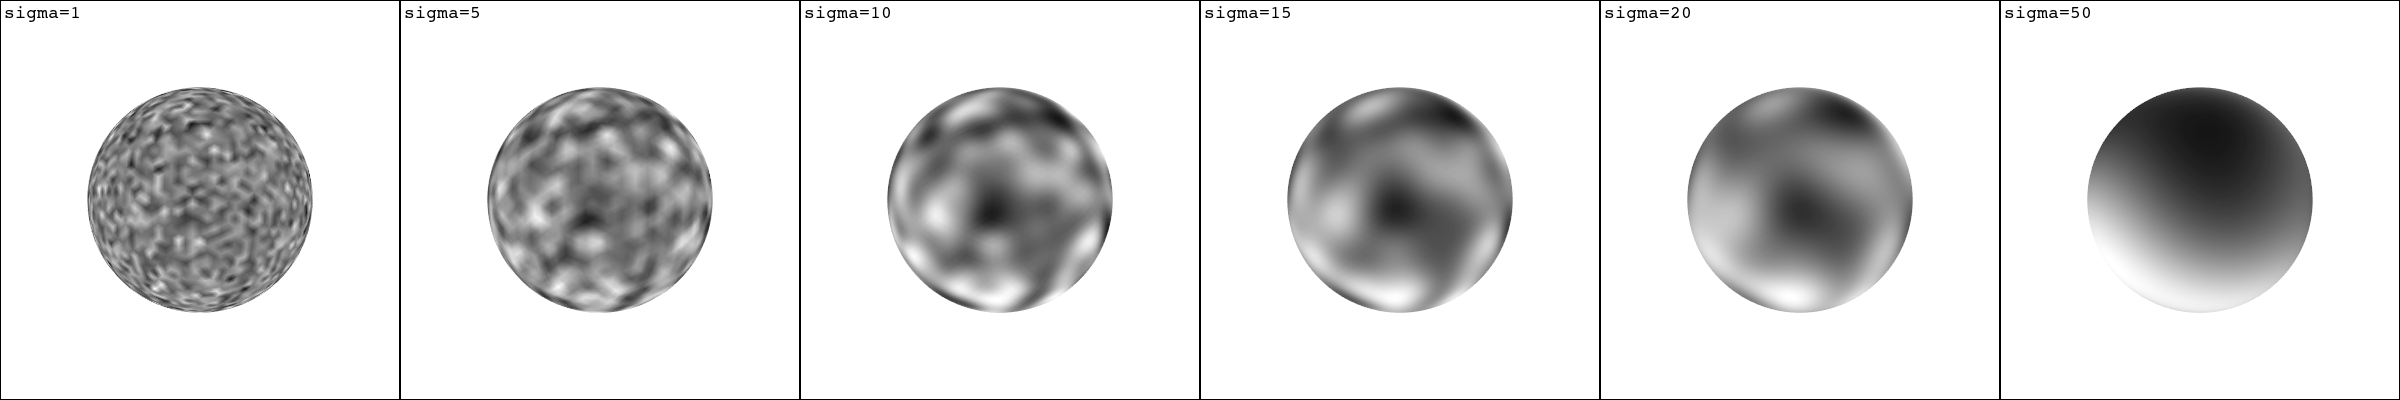

In [137]:
import copy
pl = pv.Plotter(shape=(1,6), window_size = (6*400, 400))


for s, sigma in enumerate([1, 5, 10, 15, 20, 50]):
    blurred = gaussian_blur_point_data(sphere_mesh, w, sigma, 200)

    tmp_mesh = copy.deepcopy(sphere_mesh)

    pl.subplot(0,s)
    pl.add_mesh(tmp_mesh, scalars=blurred, cmap = 'binary', **mesh_aes)
    pl.add_text(f"sigma={sigma}", font='courier', font_size = 8)
    pl.camera_position = 'yz'

pl.show(jupyter_backend='static')
pl.save_graphic(projdir + "/figs/rev_add_noise.svg")

In [119]:
import numpy as np
from scipy.spatial import cKDTree


def gaussian_blur_point_data(mesh, values, sigma, radius=None):
    """
    Blurring of mesh-embedded scalars
    """

    if radius is None:
        radius = 3.0 * sigma

    points = np.asarray(mesh.points)
    tree = cKDTree(points)
    neighborhoods = tree.query_ball_point(points, radius)

    smoothed = np.zeros(values.shape)

    # calculate gaussian weighted average
    for i, neighbors in enumerate(neighborhoods):

        neighbors = np.asarray(neighbors)
        distances = np.linalg.norm(
            points[neighbors] - points[i],
            axis=1
        )
        weights = np.exp(
            -0.5 * (distances / sigma) ** 2
        )
        weights /= weights.sum()
        smoothed[i] = np.tensordot(
            weights,
            values[neighbors],
            axes=(0, 0)
        )

    return smoothed